# MPIIGaze EDA

이 노트북은 MPIIGaze 데이터셋을 기반으로 EDA를 수행하는 예시입니다.

핵심 목표:
- 데이터 수와 사람별 구성을 확인한다.
- gaze / head pose 분포를 살펴본다.
- 눈 이미지 샘플을 시각화한다.
- 이상치와 편향을 확인한다.
- 이후 모델 학습을 위한 가설을 세운다.

In [14]:
# ============================================================
# 0. Import 및 데이터 로딩
# ============================================================

import os
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

%matplotlib inline


# ------------------------------------------------------------
# 1. 데이터 경로 설정
# ------------------------------------------------------------

ROOT = Path.cwd()

LABEL_DIR = ROOT / 'data' / 'EyeBased' / 'MPIIGaze' / 'Label'
IMG_DIR = ROOT / 'data' / 'EyeBased' / 'MPIIGaze' / 'Image'

label_paths = sorted(LABEL_DIR.glob('*.label'))

print(f'Label files: {len(label_paths)}')

for p in label_paths:
    print(p.name)


# ------------------------------------------------------------
# 2. 라벨 파일 파싱 함수
# ------------------------------------------------------------

def parse_label_file(path):
    with open(path, 'r') as f:
        lines = [line.strip() for line in f if line.strip()]

    if not lines:
        return []

    header = lines[0].split()
    rows = []

    for line in lines[1:]:
        parts = line.split()

        if len(parts) != len(header):
            continue

        row = dict(zip(header, parts))

        for key in [
            '2DGaze', '2DHead', '3DHead',
            'Rmat', 'Smat', 'GazeOrigin'
        ]:
            if key in row:
                row[key] = np.array(
                    [float(x) for x in row[key].split(',')],
                    dtype=np.float32
                )

        rows.append(row)

    return rows


# ------------------------------------------------------------
# 3. 전체 데이터 레코드 생성
# ------------------------------------------------------------

records = []

for label_path in label_paths:
    person = label_path.stem
    rows = parse_label_file(label_path)

    for row in rows:
        img_name = row['Image']

        records.append({
            'person': person,
            'image_path': IMG_DIR / img_name,
            'gaze': row['2DGaze'],
            'head': row['2DHead'],
            'eye': row['WhichEye']
        })

print(f'\nTotal samples: {len(records)}')


# ------------------------------------------------------------
# 4. 사람별 샘플 수 계산
# ------------------------------------------------------------

person_counts = {}

for r in records:
    person = r['person']
    person_counts[person] = person_counts.get(person, 0) + 1

print('\nSamples per person:')

for person, count in sorted(person_counts.items()):
    print(f'{person}: {count}')


# ------------------------------------------------------------
# 5. 분석용 배열 생성
# ------------------------------------------------------------

gaze = np.stack([r['gaze'] for r in records], axis=0)
head = np.stack([r['head'] for r in records], axis=0)

print('\nGaze shape:', gaze.shape)
print('Head shape:', head.shape)

print('Gaze dtype:', gaze.dtype)
print('Head dtype:', head.dtype)

Label files: 15
p00.label
p01.label
p02.label
p03.label
p04.label
p05.label
p06.label
p07.label
p08.label
p09.label
p10.label
p11.label
p12.label
p13.label
p14.label

Total samples: 45000

Samples per person:
p00: 3000
p01: 3000
p02: 3000
p03: 3000
p04: 3000
p05: 3000
p06: 3000
p07: 3000
p08: 3000
p09: 3000
p10: 3000
p11: 3000
p12: 3000
p13: 3000
p14: 3000

Gaze shape: (45000, 2)
Head shape: (45000, 2)
Gaze dtype: float32
Head dtype: float32


In [15]:
# ============================================================
# 1-1. Gaze 기술통계
# ============================================================

# 라디안 -> 도 단위 변환
gaze_deg = np.rad2deg(gaze)

gaze_stats = pd.DataFrame({
    'Yaw (degrees)': gaze_deg[:, 0],
    'Pitch (degrees)': gaze_deg[:, 1]
})

display(
    gaze_stats.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).T.round(3)
)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Yaw (degrees),45000.0,0.033,8.688,-41.531,-16.680,-13.506,-7.199,0.128,7.244,13.286,16.642,38.716
Pitch (degrees),45000.0,-8.747,5.199,-22.764,-18.488,-16.871,-13.067,-8.781,-4.384,-0.699,1.026,4.763


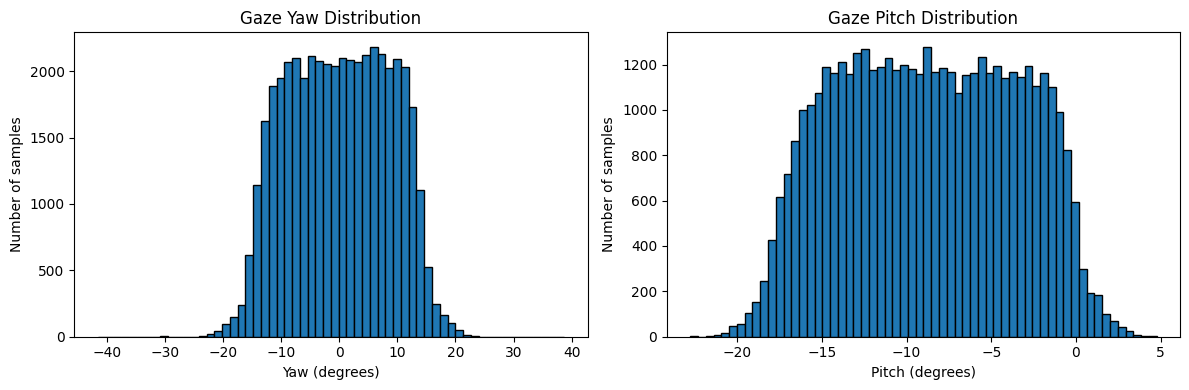

In [16]:
# ============================================================
# 1-2. Gaze 히스토그램
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(gaze_deg[:, 0], bins=60, edgecolor='black')
axes[0].set_title('Gaze Yaw Distribution')
axes[0].set_xlabel('Yaw (degrees)')
axes[0].set_ylabel('Number of samples')

axes[1].hist(gaze_deg[:, 1], bins=60, edgecolor='black')
axes[1].set_title('Gaze Pitch Distribution')
axes[1].set_xlabel('Pitch (degrees)')
axes[1].set_ylabel('Number of samples')

plt.tight_layout()
plt.show()

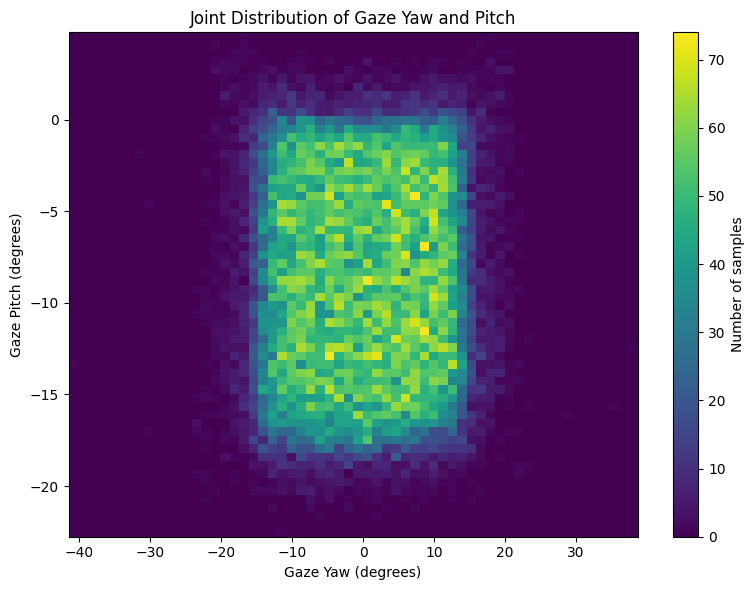

In [17]:
# ============================================================
# 1-3. Gaze 2차원 분포
# ============================================================

plt.figure(figsize=(8, 6))

plt.hist2d(
    gaze_deg[:, 0],
    gaze_deg[:, 1],
    bins=60,
    cmap='viridis'
)

plt.colorbar(label='Number of samples')
plt.xlabel('Gaze Yaw (degrees)')
plt.ylabel('Gaze Pitch (degrees)')
plt.title('Joint Distribution of Gaze Yaw and Pitch')

plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# 2-1. 사람별 기술통계
# ============================================================

person_rows = []

for person in sorted(person_counts):
    person_records = [
        r for r in records
        if r['person'] == person
    ]

    pgaze = np.stack([r['gaze'] for r in person_records])
    phead = np.stack([r['head'] for r in person_records])

    person_rows.append({
        'person': person,
        'count': len(person_records),

        'gaze_yaw_mean': pgaze[:, 0].mean(),
        'gaze_yaw_std': pgaze[:, 0].std(),
        'gaze_pitch_mean': pgaze[:, 1].mean(),
        'gaze_pitch_std': pgaze[:, 1].std(),

        'head_yaw_mean': phead[:, 0].mean(),
        'head_yaw_std': phead[:, 0].std(),
        'head_pitch_mean': phead[:, 1].mean(),
        'head_pitch_std': phead[:, 1].std()
    })

person_df = pd.DataFrame(person_rows).set_index('person')

# 각도 관련 통계를 라디안에서 도 단위로 변환
angle_cols = [
    col for col in person_df.columns
    if col != 'count'
]

person_df[angle_cols] = np.rad2deg(person_df[angle_cols])

display(person_df.round(3))

,count,gaze_yaw_mean,gaze_yaw_std,gaze_pitch_mean,gaze_pitch_std,head_yaw_mean,head_yaw_std,head_pitch_mean,head_pitch_std
person,,,,,,,,,
p00,3000,-0.374,7.976,-7.614,4.570,-0.925,5.527,9.442000,9.719
p01,3000,-0.044,8.006,-9.487,4.883,-2.063,4.109,11.102000,15.263
p02,3000,-0.188,8.170,-6.789,4.964,-0.977,3.445,5.956000,9.551
p03,3000,0.476,8.886,-9.234,5.424,-1.914,3.844,19.357000,14.679
p04,3000,0.007,8.436,-8.567,5.024,-3.204,6.178,8.171000,10.861
p05,3000,0.266,9.313,-8.870,5.291,0.640,9.517,8.467000,7.324
p06,3000,-0.239,9.518,-10.505,5.679,-3.603,7.626,10.043000,10.020
p07,3000,-0.248,9.131,-9.495,5.204,-1.361,2.717,25.382999,17.650
p08,3000,0.263,9.073,-9.966,5.354,-1.511,7.202,14.617000,13.162


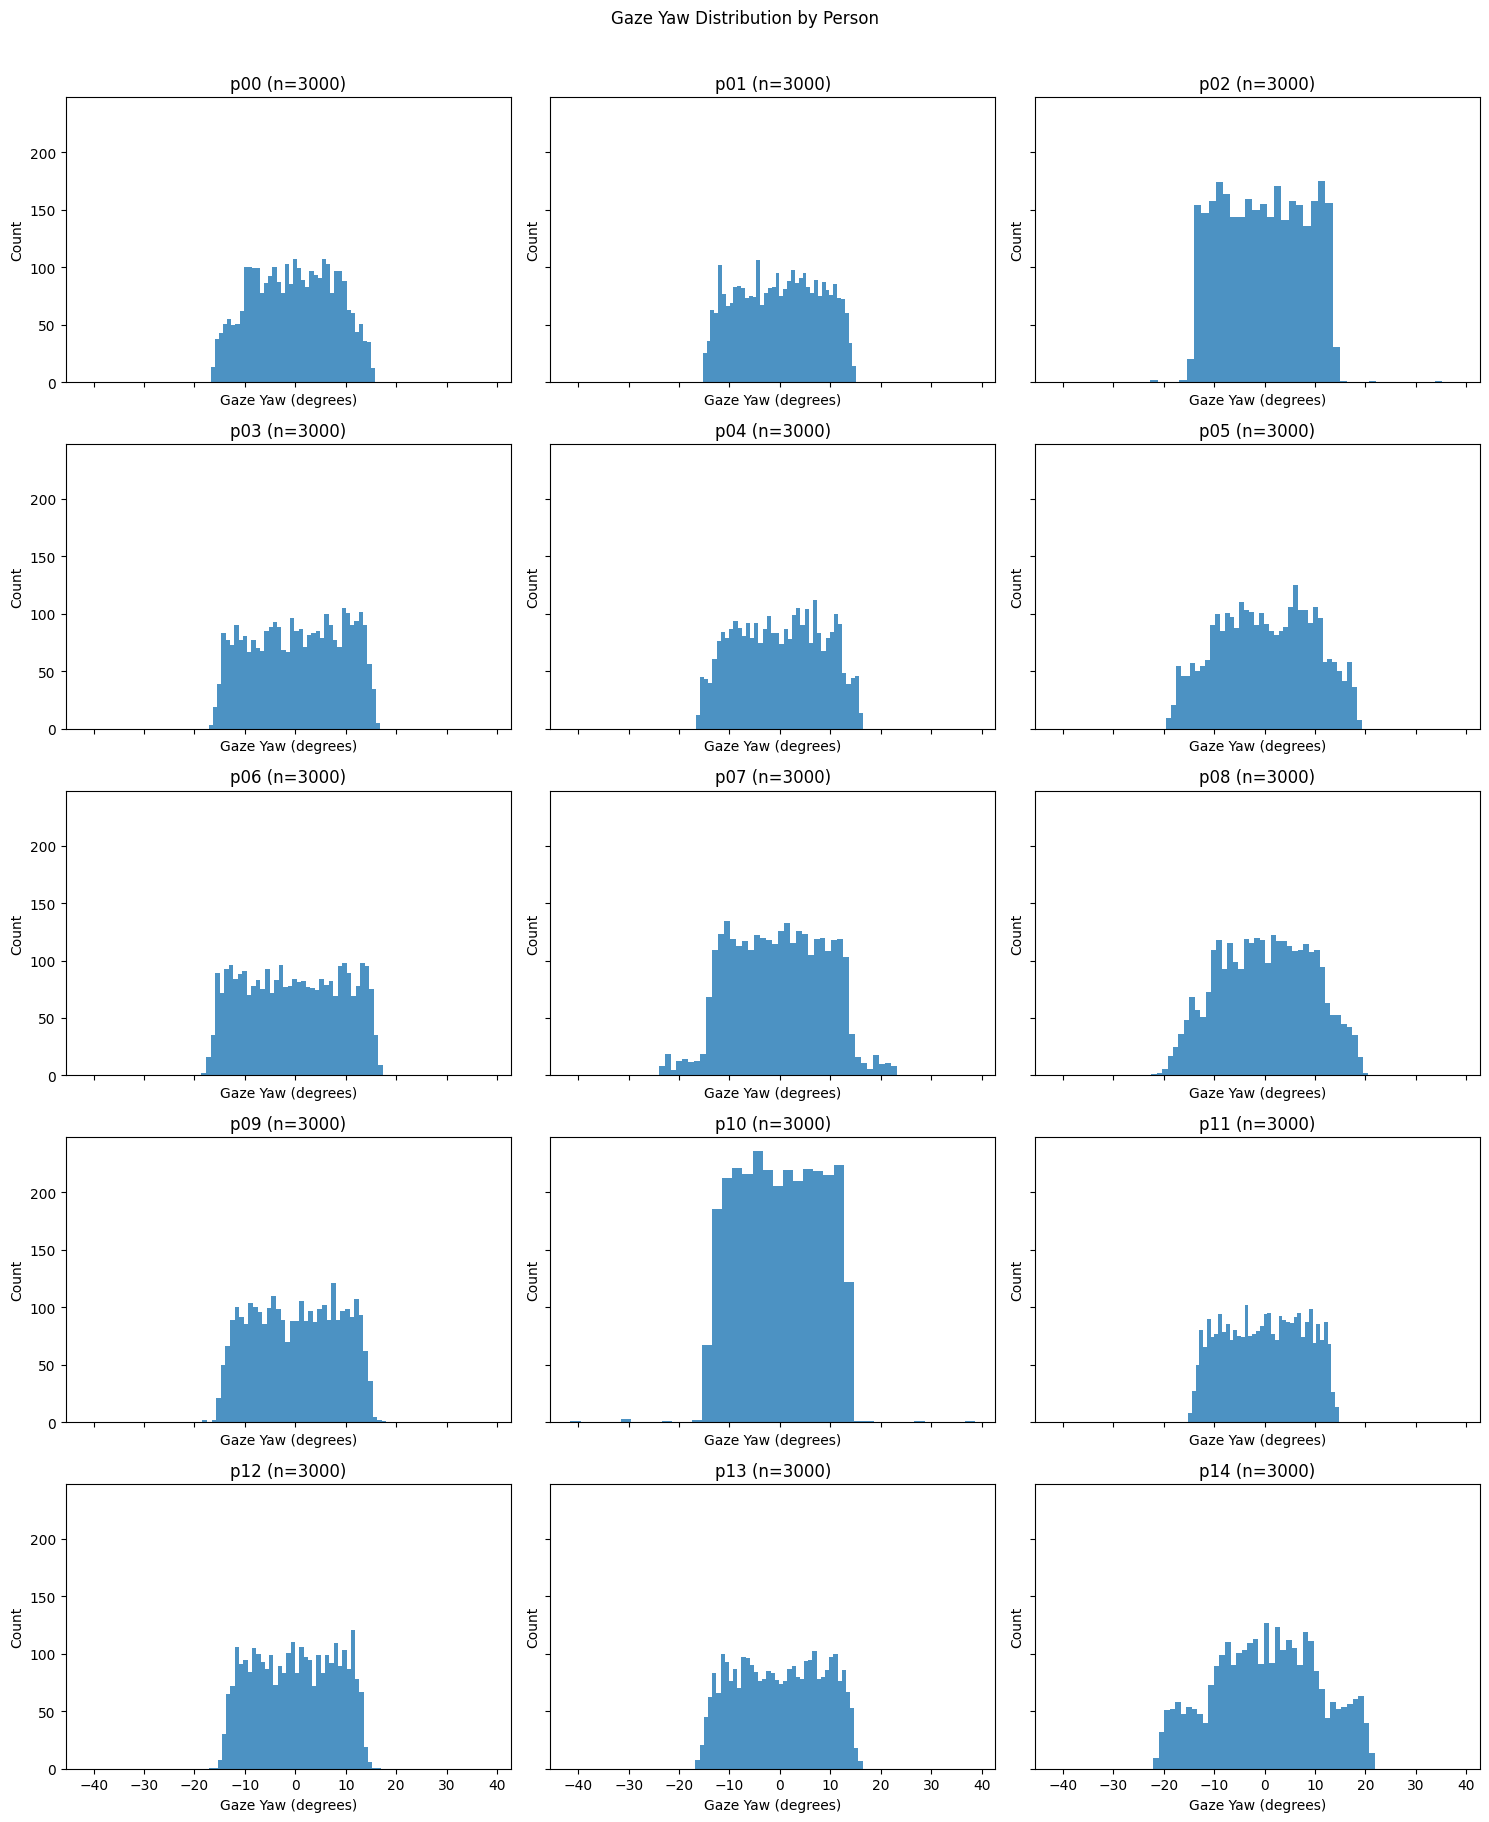

In [24]:
# ============================================================
# 3-1. 사람별 Gaze Yaw 분포
# ============================================================

persons = sorted(person_counts.keys())

fig, axes = plt.subplots(5, 3, figsize=(15, 18), sharex=True, sharey=True)
axes = axes.flatten()

for i, person in enumerate(persons):
    person_gaze = np.stack([
        r['gaze'] for r in records
        if r['person'] == person
    ])

    axes[i].hist(
        np.rad2deg(person_gaze[:, 0]),
        bins=40,
        alpha=0.8
    )

    axes[i].set_title(f'{person} (n={len(person_gaze)})')
    axes[i].set_xlabel('Gaze Yaw (degrees)')
    axes[i].set_ylabel('Count')

plt.suptitle('Gaze Yaw Distribution by Person', y=1.01)
plt.tight_layout()
plt.show()

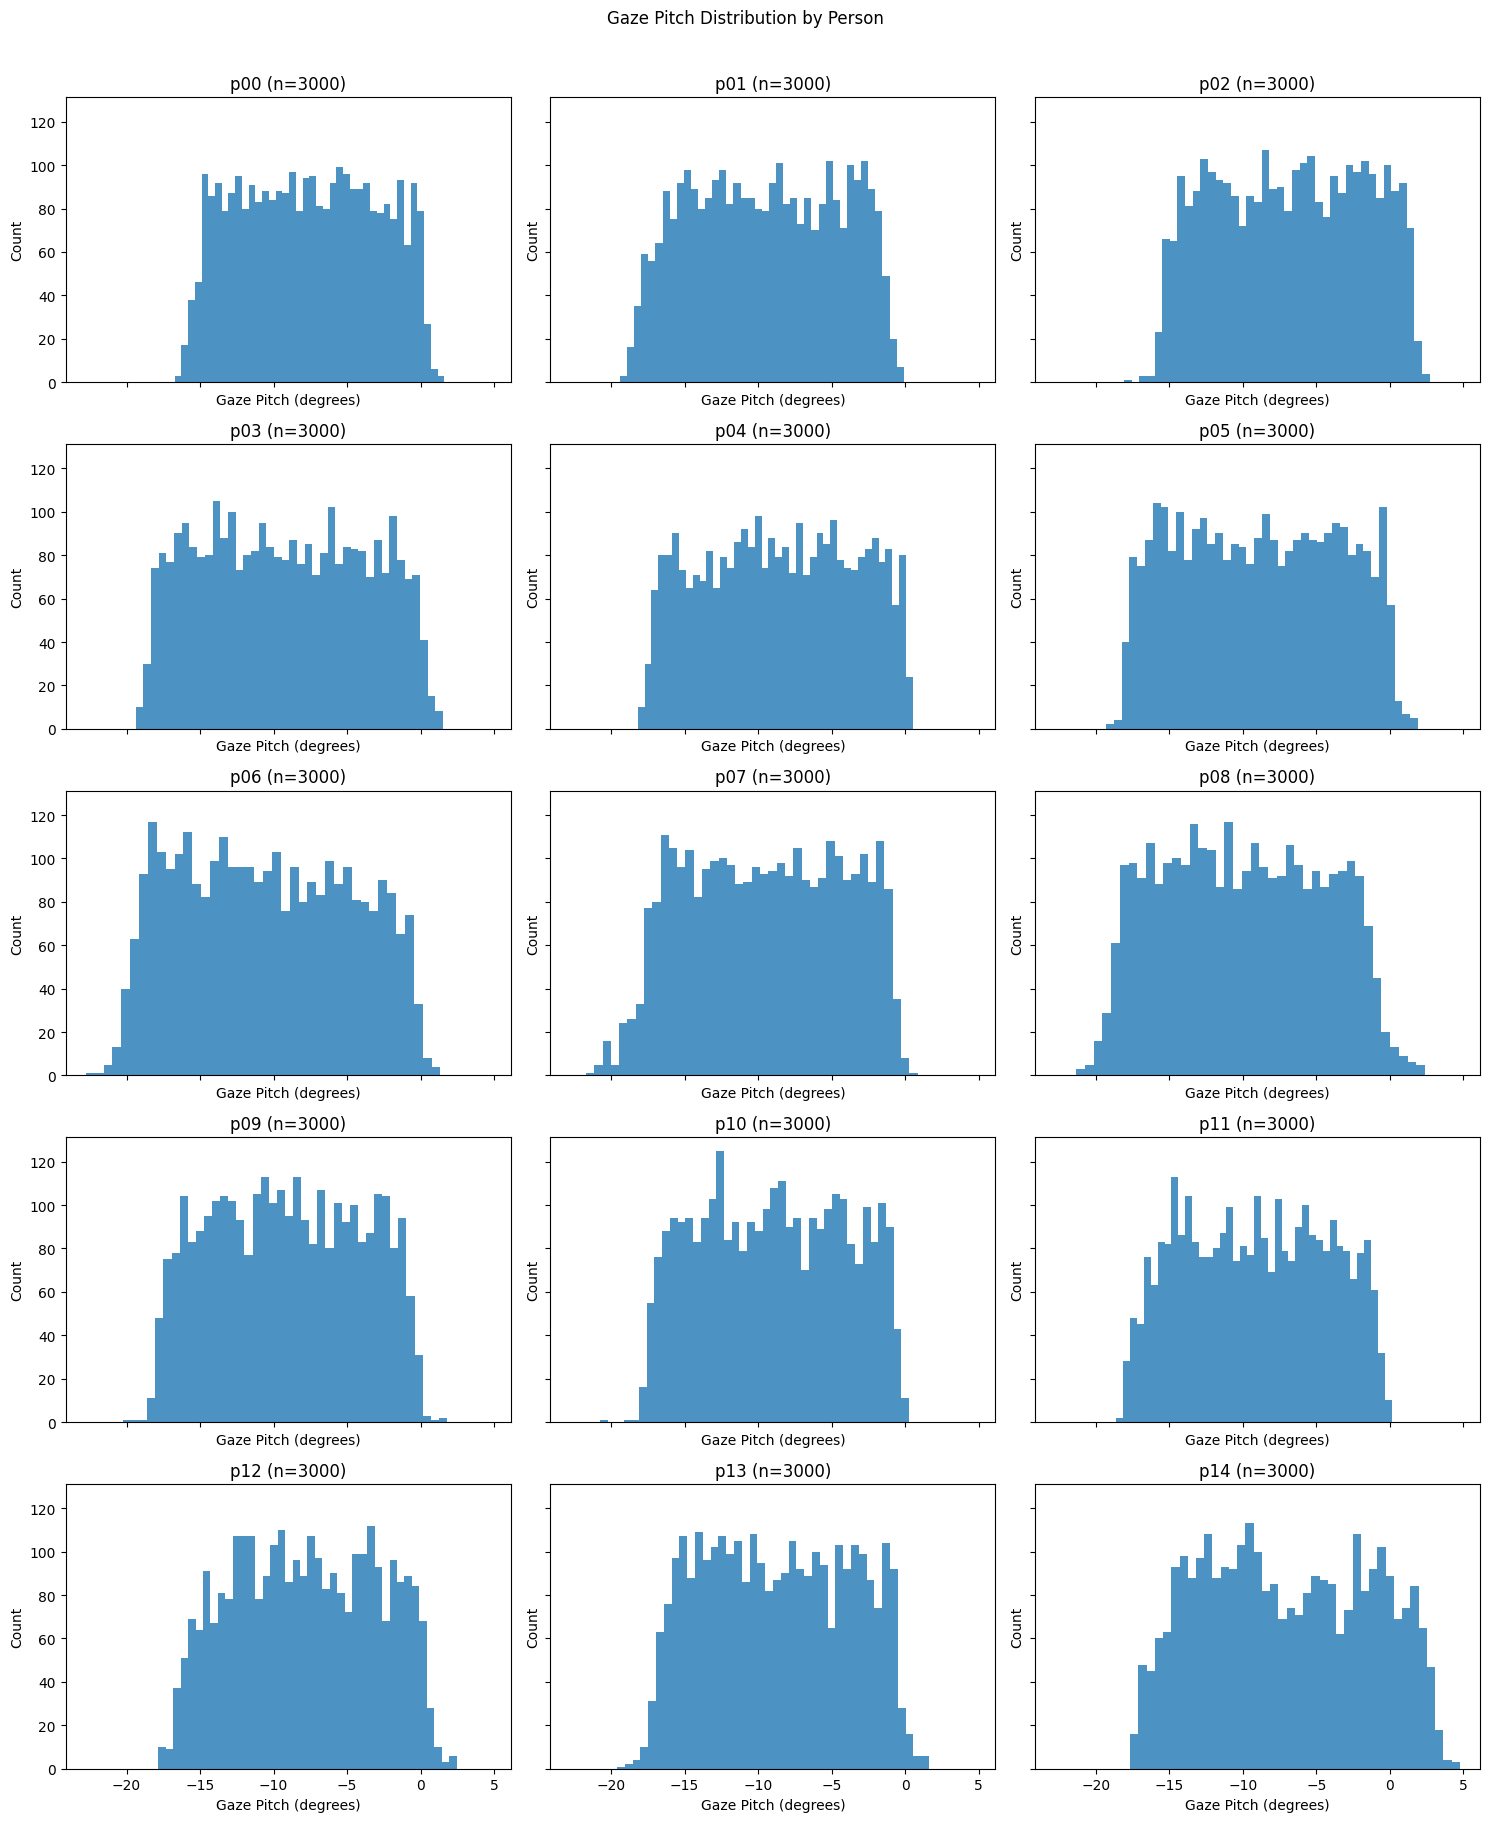

In [25]:
# ============================================================
# 3-2. 사람별 Gaze Pitch 분포
# ============================================================

fig, axes = plt.subplots(5, 3, figsize=(15, 18), sharex=True, sharey=True)
axes = axes.flatten()

for i, person in enumerate(persons):
    person_gaze = np.stack([
        r['gaze'] for r in records
        if r['person'] == person
    ])

    axes[i].hist(
        np.rad2deg(person_gaze[:, 1]),
        bins=40,
        alpha=0.8
    )

    axes[i].set_title(f'{person} (n={len(person_gaze)})')
    axes[i].set_xlabel('Gaze Pitch (degrees)')
    axes[i].set_ylabel('Count')

plt.suptitle('Gaze Pitch Distribution by Person', y=1.01)
plt.tight_layout()
plt.show()

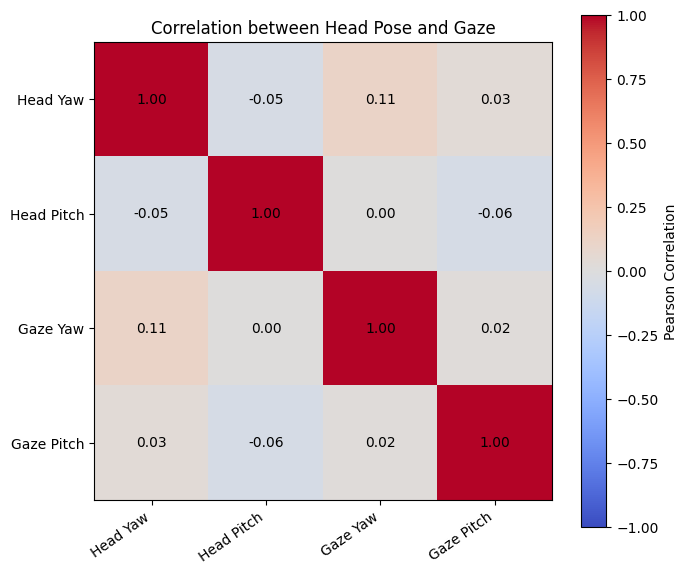

In [26]:
head_deg = np.rad2deg(head)
gaze_deg = np.rad2deg(gaze)

# 열 순서: Head Yaw, Head Pitch, Gaze Yaw, Gaze Pitch
features = np.column_stack([
    head_deg[:, 0],
    head_deg[:, 1],
    gaze_deg[:, 0],
    gaze_deg[:, 1]
])

feature_names = ['Head Yaw', 'Head Pitch', 'Gaze Yaw', 'Gaze Pitch']
corr = np.corrcoef(features, rowvar=False)

plt.figure(figsize=(7, 6))
plt.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
plt.colorbar(label='Pearson Correlation')
plt.xticks(range(4), feature_names, rotation=35, ha='right')
plt.yticks(range(4), feature_names)
plt.title('Correlation between Head Pose and Gaze')
for i in range(4):
    for j in range(4):
        plt.text(j, i, f'{corr[i, j]:.2f}',
                 ha='center', va='center', color='black')
plt.tight_layout()
plt.show()

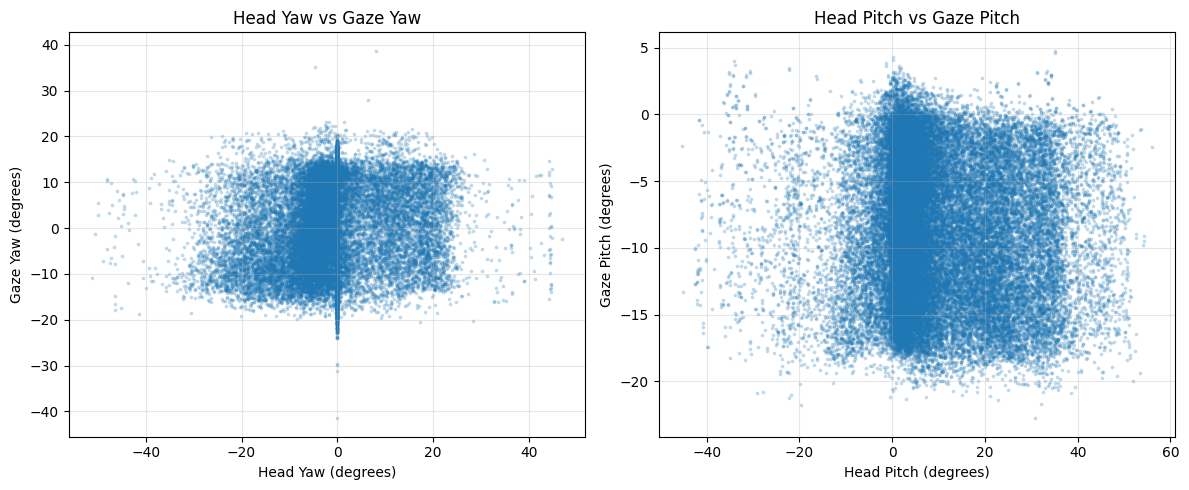

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(head_deg[:, 0], gaze_deg[:, 0],
                s=3, alpha=0.2)
axes[0].set_xlabel('Head Yaw (degrees)')
axes[0].set_ylabel('Gaze Yaw (degrees)')
axes[0].set_title('Head Yaw vs Gaze Yaw')
axes[0].grid(alpha=0.3)

axes[1].scatter(head_deg[:, 1], gaze_deg[:, 1],
                s=3, alpha=0.2)
axes[1].set_xlabel('Head Pitch (degrees)')
axes[1].set_ylabel('Gaze Pitch (degrees)')
axes[1].set_title('Head Pitch vs Gaze Pitch')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
# Pearson 상관계수
yaw_corr = np.corrcoef(head_deg[:, 0], gaze_deg[:, 0])[0, 1]
pitch_corr = np.corrcoef(head_deg[:, 1], gaze_deg[:, 1])[0, 1]

# Spearman 상관계수: 순위 기반의 단조 관계
from scipy.stats import spearmanr

yaw_spearman = spearmanr(head_deg[:, 0], gaze_deg[:, 0]).statistic
pitch_spearman = spearmanr(head_deg[:, 1], gaze_deg[:, 1]).statistic

print(f'Yaw Pearson correlation:   {yaw_corr:.4f}')
print(f'Yaw Spearman correlation:  {yaw_spearman:.4f}')
print(f'Pitch Pearson correlation:  {pitch_corr:.4f}')
print(f'Pitch Spearman correlation: {pitch_spearman:.4f}')

Yaw Pearson correlation:   0.1132
Yaw Spearman correlation:  0.0962
Pitch Pearson correlation:  -0.0614
Pitch Spearman correlation: -0.0649
